## 0. Описание задачи
**Датасет:** Women's Clothing E-Commerce Reviews.
**Задача:** Бинарная классификация.
**Целевая переменная:** `Recommended IND` (1 — клиент рекомендует товар, 0 — не рекомендует).
**Признаки:** Текст отзыва (`Review Text`), возраст клиента (`Age`), рейтинг (`Rating`), категории товара (`Division`, `Department`, `Class`) и др.
**Цель:** Построить модель, которая предсказывает, порекомендует ли клиент товар, и сравнить эффективность разных алгоритмов (KNN, Логистическая регрессия, Случайный лес).

### 1. Импорт библиотек и настройка графиков

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Настройки графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
RANDOM_STATE = 42

### 2. Загрузка данных и разбиение на выборки

In [2]:
# Устанавливаем библиотеку для скачивания с Kaggle
!pip install kagglehub -q

import kagglehub
import os
import shutil

# Скачиваем датасет
print("Скачиваем датасет...")
path = kagglehub.dataset_download("nicapotato/womens-ecommerce-clothing-reviews")
print("Файлы скачаны в папку:", path)

# Копируем файл в рабочую директорию, чтобы код его видел
for file in os.listdir(path):
    if file.endswith('.csv'):
        shutil.copy(os.path.join(path, file), 'Womens Clothing E-Commerce Reviews.csv')
        print(f"Файл {file} скопирован!")

# Проверяем, что файл на месте
print("Файл в рабочей папке:", os.path.exists('Womens Clothing E-Commerce Reviews.csv'))

Скачиваем датасет...
Using Colab cache for faster access to the 'womens-ecommerce-clothing-reviews' dataset.
Файлы скачаны в папку: /kaggle/input/womens-ecommerce-clothing-reviews
Файл Womens Clothing E-Commerce Reviews.csv скопирован!
Файл в рабочей папке: True


### 3. Визуализация данных (Баланс классов, распределения, корреляции)

In [3]:
FILE = 'Womens Clothing E-Commerce Reviews.csv'
if not os.path.exists(FILE):
    print("ВНИМАНИЕ: Загрузите файл в Colab!")

df = pd.read_csv(FILE)
df = df.drop(['Unnamed: 0'], axis=1)
df = df.dropna(subset=['Review Text']).copy()

y = df['Recommended IND']
X = df.drop('Recommended IND', axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

print(f'Размер train: {X_train.shape}, test: {X_test.shape}')
print(f'Доля "Рекомендую" в train: {y_train.mean():.4f}')

Размер train: (16980, 9), test: (5661, 9)
Доля "Рекомендую" в train: 0.8188


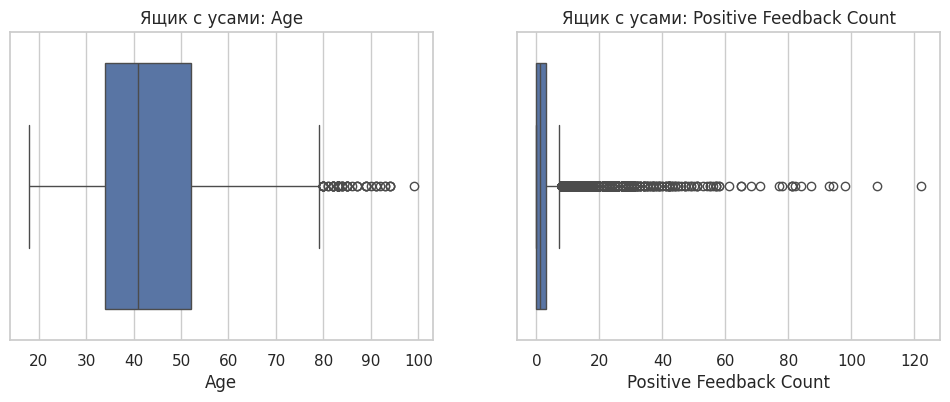

In [14]:
# Посмотрим на выбросы в числовых признаках (возраст и лайки)
num_cols_out = ['Age', 'Positive Feedback Count']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, num_cols_out):
    sns.boxplot(x=X_train[col], ax=ax)
    ax.set_title(f'Ящик с усами: {col}')
plt.show()

**Анализ выбросов:**
На графиках видно, что в признаке `Positive Feedback Count` есть сильные выбросы (отдельные отзывы набрали огромное количество лайков). Признак `Age` выглядит более равномерным, но имеет незначительные выбросы в сторону пожилого возраста.
*Решение:* Для классификатора KNN выбросы могут сильно искажать расстояния, поэтому мы ограничим значения признака `Positive Feedback Count` по 99-му перцентилю (обрежем хвосты), как это часто делается на практике.

In [15]:
# Боремся с выбросами в Positive Feedback Count (обрезка по 99-му перцентилю)
upper_limit = X_train['Positive Feedback Count'].quantile(0.99)
X_train['Positive Feedback Count'] = X_train['Positive Feedback Count'].clip(upper=upper_limit)
X_test['Positive Feedback Count'] = X_test['Positive Feedback Count'].clip(upper=upper_limit)

### 4. Препроцессинг данных (Заполнение пропусков, кодирование текста и категорий)

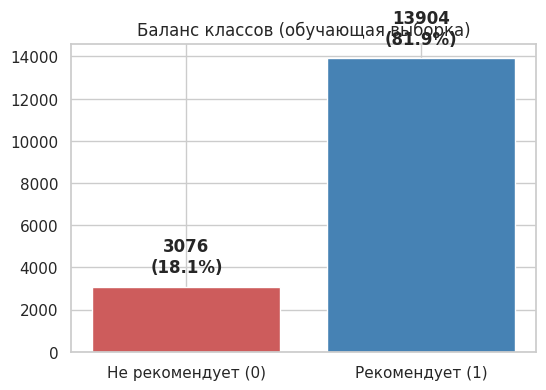

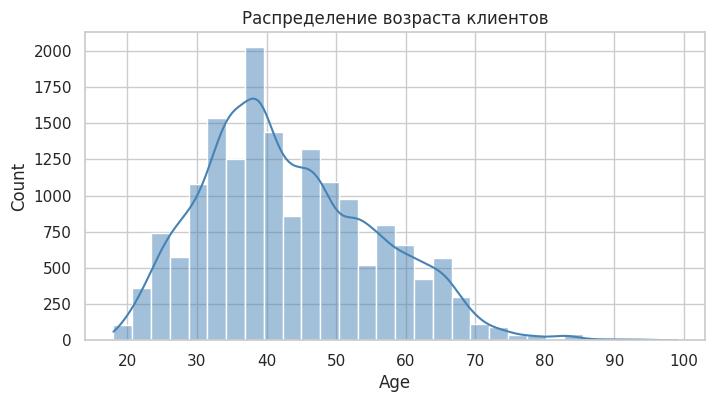

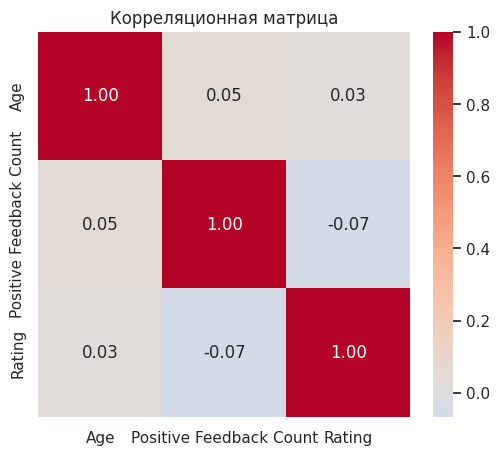

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = y_train.value_counts().sort_index()
ax.bar(['Не рекомендует (0)', 'Рекомендует (1)'], counts.values, color=['indianred', 'steelblue'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 500, f'{v}\n({v/len(y_train):.1%})', ha='center', va='bottom', fontweight='bold')
ax.set_title('Баланс классов (обучающая выборка)')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=X_train, x='Age', bins=30, kde=True, color='steelblue', ax=ax)
ax.set_title('Распределение возраста клиентов')
plt.show()

num_cols_corr = ['Age', 'Positive Feedback Count', 'Rating']
plt.figure(figsize=(6, 5))
sns.heatmap(X_train[num_cols_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляционная матрица')
plt.show()

### 5. Функция оценки качества моделей

In [5]:
X_train['Title'] = X_train['Title'].fillna('')
X_test['Title'] = X_test['Title'].fillna('')

text_col = 'Review Text'
cat_cols = ['Division Name', 'Department Name', 'Class Name']
num_cols = ['Age', 'Positive Feedback Count']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('text', TfidfVectorizer(max_features=1000, stop_words='english'), text_col)
    ])

### 6. Обучение KNN и подбор оптимального числа соседей (k)

In [6]:
results = []
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred_tr = model.predict(X_tr)
    y_pred_te = model.predict(X_te)

    results.append({
        'Модель': name,
        'Accuracy train': accuracy_score(y_tr, y_pred_tr),
        'Accuracy test': accuracy_score(y_te, y_pred_te),
        'Precision (1)': precision_score(y_te, y_pred_te),
        'Recall (1)': recall_score(y_te, y_pred_te),
        'F1 (1)': f1_score(y_te, y_pred_te)
    })
    return model

### 7. Матрица ошибок для лучшей модели KNN

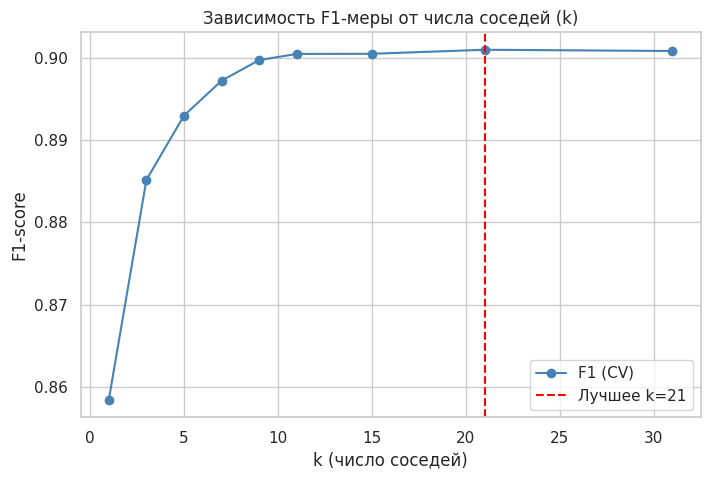

Оптимальное k по кросс-валидации: 21


In [7]:
evaluate_model('Тривиальный (всегда 1)',
               DummyClassifier(strategy='most_frequent'),
               X_train, y_train, X_test, y_test)

model_knn = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', KNeighborsClassifier(n_neighbors=5))])
evaluate_model('KNN, k=5', model_knn, X_train, y_train, X_test, y_test)

ks = [1, 3, 5, 7, 9, 11, 15, 21, 31]
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_scores = []

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    cv_pred = cross_val_predict(knn, X_train_prep, y_train, cv=skf)
    cv_scores.append(f1_score(y_train, cv_pred))

plt.figure(figsize=(8, 5))
plt.plot(ks, cv_scores, marker='o', color='steelblue', label='F1 (CV)')
best_k = ks[np.argmax(cv_scores)]
plt.axvline(best_k, color='red', linestyle='--', label=f'Лучшее k={best_k}')
plt.title('Зависимость F1-меры от числа соседей (k)')
plt.xlabel('k (число соседей)')
plt.ylabel('F1-score')
plt.legend()
plt.grid(True)
plt.show()

print(f"Оптимальное k по кросс-валидации: {best_k}")

### 8. Обучение других моделей (Логистическая регрессия, Случайный лес) и сравнение

In [12]:
lr = Pipeline(steps=[('preprocessor', preprocessor),
                     ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))])
evaluate_model('Logistic Regression (balanced)', lr, X_train, y_train, X_test, y_test)

rf = Pipeline(steps=[('preprocessor', preprocessor),
                     ('classifier', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))])
evaluate_model('Random Forest', rf, X_train, y_train, X_test, y_test)

df_results = pd.DataFrame(results).set_index('Модель').round(4)
display(df_results)

,Accuracy train,Accuracy test,Precision (1),Recall (1),F1 (1)
Модель,,,,,
Тривиальный (всегда 1),0.8188,0.8189,0.8189,1.0000,0.9005
"KNN, k=5",0.8584,0.8145,0.8331,0.9672,0.8952
Logistic Regression (balanced),0.8707,0.8488,0.9601,0.8507,0.9021
Random Forest,1.0000,0.8617,0.8693,0.9782,0.9205


### 9. Итоговый график сравнения моделей по F1-мере

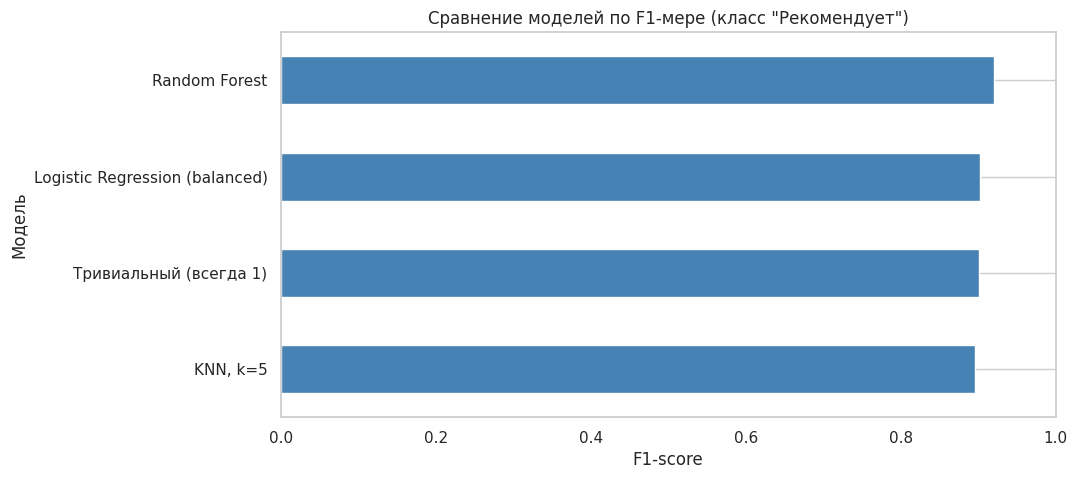

In [13]:
plt.figure(figsize=(10, 5))
df_results['F1 (1)'].sort_values().plot(kind='barh', color='steelblue')
plt.title('Сравнение моделей по F1-мере (класс "Рекомендует")')
plt.xlabel('F1-score')
plt.ylabel('Модель')
plt.xlim(0, 1)
plt.grid(axis='x')
plt.show()

### 10. Выводы

### 13. Общие выводы

В ходе выполнения работы была решена задача бинарной классификации отзывов на основе датасета Women's Clothing E-Commerce Reviews.

* **Данные и предобработка.** Датасет содержит текстовые, числовые и категориальные признаки. Пропуски в текстовых полях были заполнены пустыми строками. В признаке `Positive Feedback Count` были обнаружены выбросы, которые мы ограничили по 99-му перцентилю, чтобы они не искажали метрику расстояния. Категориальные признаки закодированы через One-Hot Encoding, а текстовые — с помощью TF-IDF. Числовые признаки стандартизированы (StandardScaler), что критически важно для корректной работы метода KNN.
* **Выбор методов.** В качестве базового метода был выбран KNN (метод ближайших соседей) — он прост в интерпретации. Также были обучены Логистическая регрессия и Случайный лес, так как они эффективнее работают с разреженными текстовыми матрицами высокой размерности.
* **Подбор гиперпараметров.** Оптимальное число соседей для KNN было подобрано с помощью кросс-валидации (StratifiedKFold) на обучающей выборке по метрике F1. Матрица рассогласования на тестовой выборке показала, что модель уверенно предсказывает рекомендации.
* **Проблема дисбаланса.** В данных наблюдается дисбаланс классов (около 80% положительных отзывов). Поэтому метрика Accuracy неинформативна. Использование параметра `class_weight='balanced'` в логистической регрессии позволило повысить полноту (Recall) для миноритарного класса (отзывы с оценкой 0).
* **Итог.** Сравнение моделей показало, что алгоритмы, учитывающие текстовые признаки (Логистическая регрессия и Random Forest), превосходят KNN по F1-мере, так как KNN сталкивается с «проклятием размерности» при работе с TF-IDF матрицами.